In [13]:
import pickle
import pandas as pd
import numpy as np
import tqdm
from collections import defaultdict
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score
from sklearn.cluster import KMeans
from sklearn_extra.cluster import KMedoids
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import normalize

In [2]:
def visualize_metrics(df, model_name, metric_name, save = False):
    df_sorted = df.sort_index()
    means = df_sorted.mean(axis=1)
    stds = df_sorted.std(axis=1)
    
    layers = df_sorted.index
    
    plt.figure()
    plt.bar(
        layers,
        means,
        yerr=stds,
        capsize=8,                 
        error_kw={
            "elinewidth": 0.5,      
            "capthick": 1,         
            "alpha": 0.6
        }
    )
    
    plt.title(f"{metric_name} for different layers of {model_name}")
    plt.xlabel("Layer number")
    plt.ylabel("Value")

    plt.xticks(layers, rotation=90)
    plt.tight_layout()
    if save:
        plt.savefig(f'../data/metrics/compare_metrics/{model_name}_{metric_name}.png')
    plt.show()

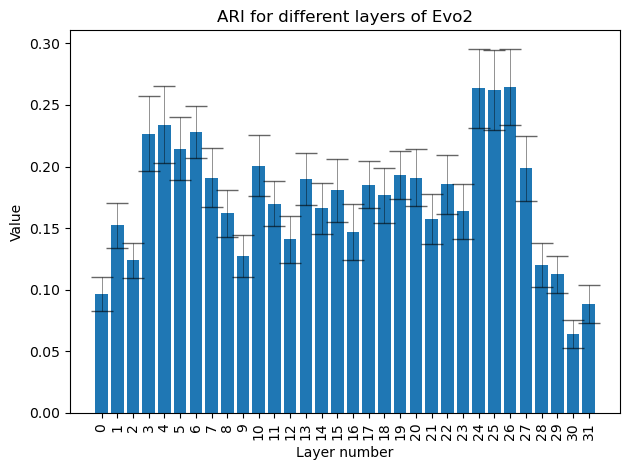

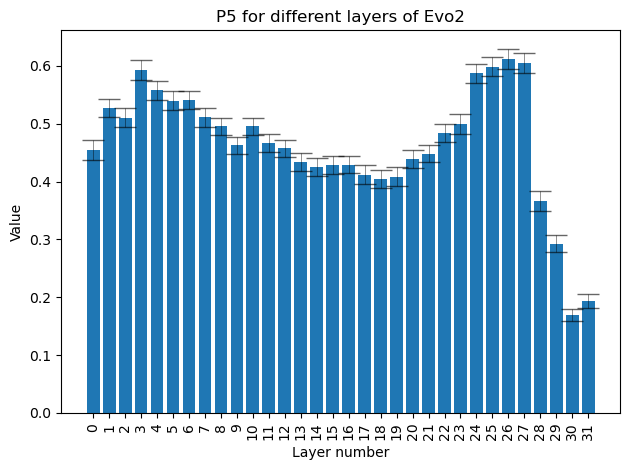

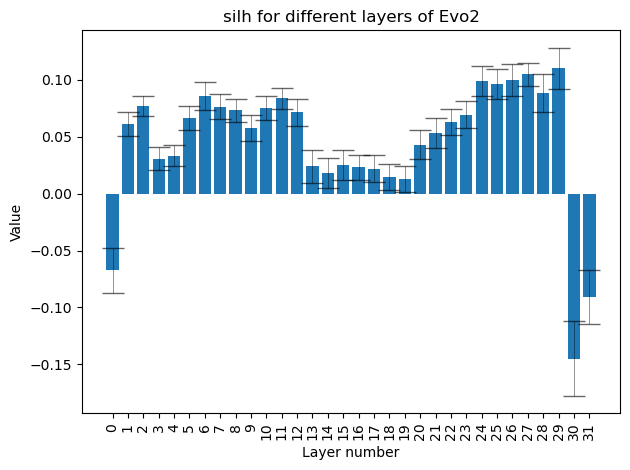

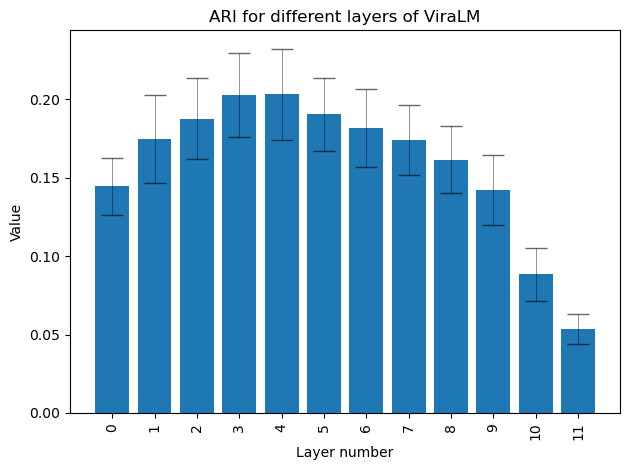

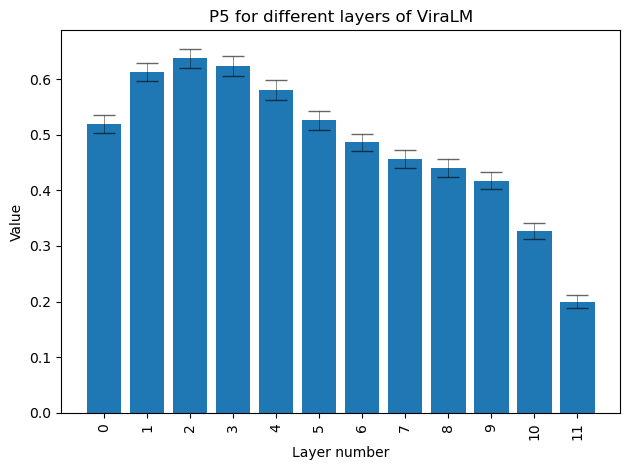

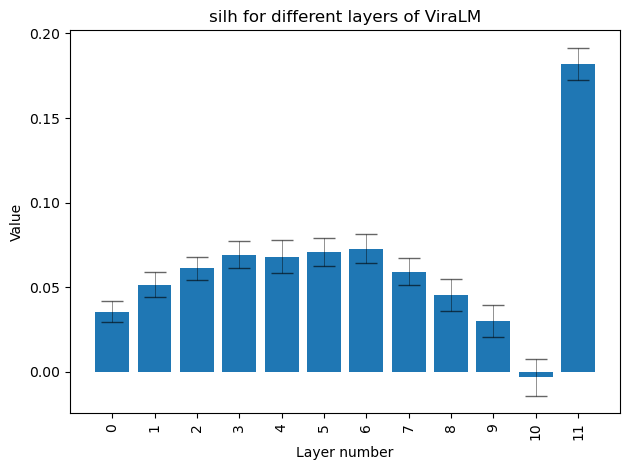

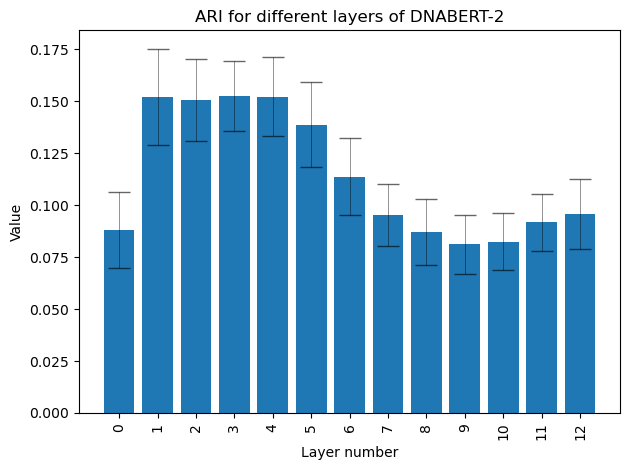

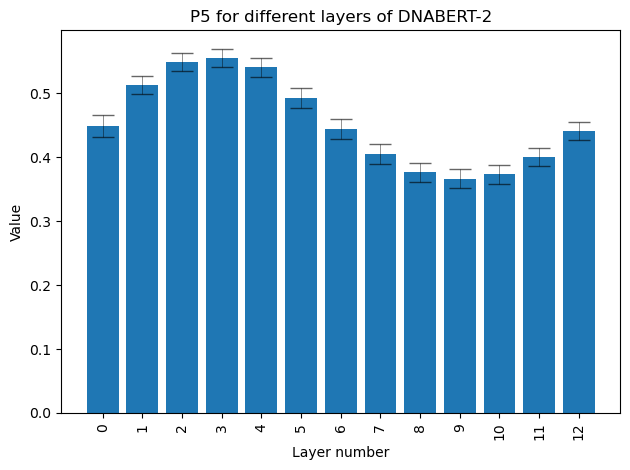

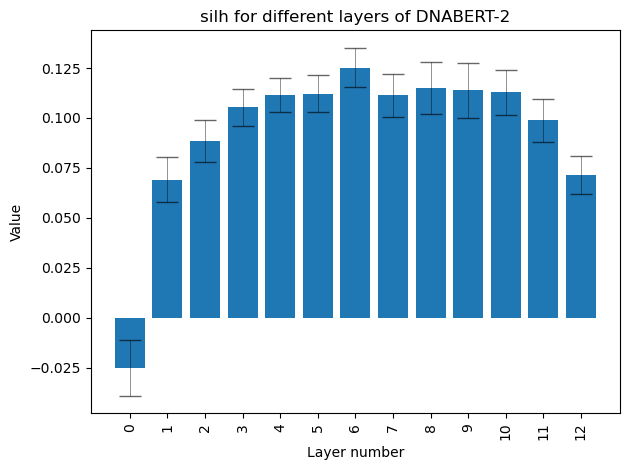

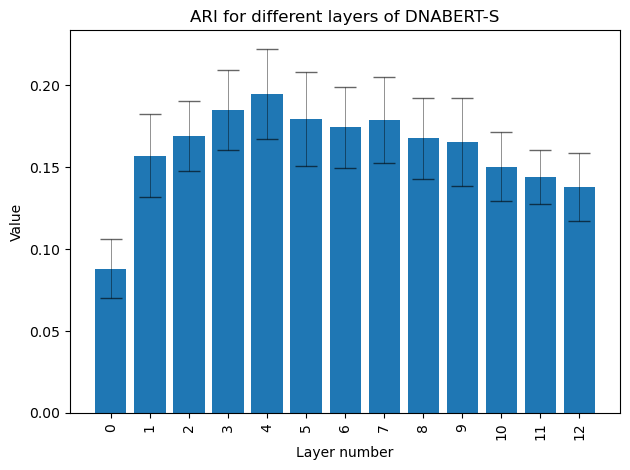

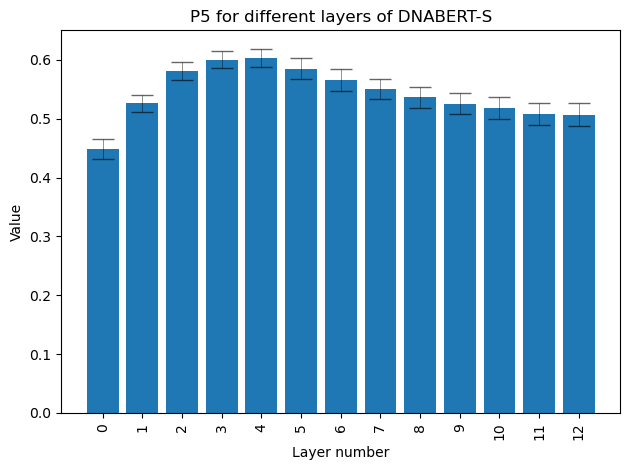

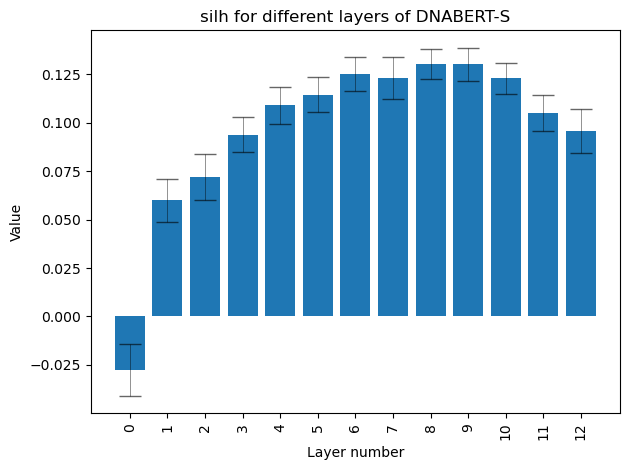

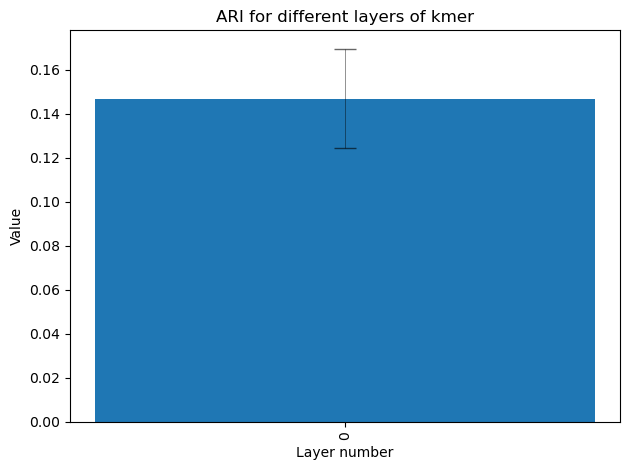

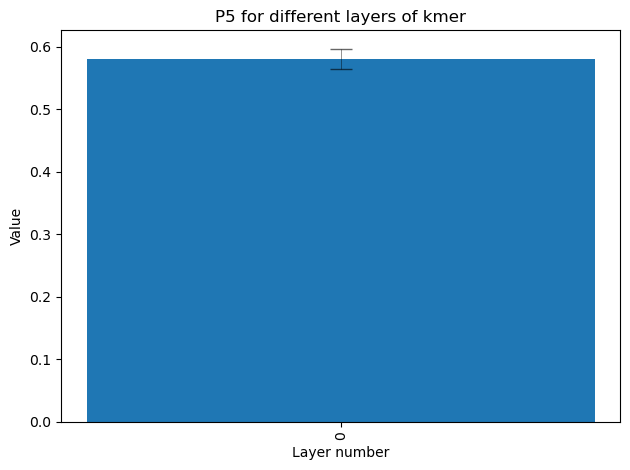

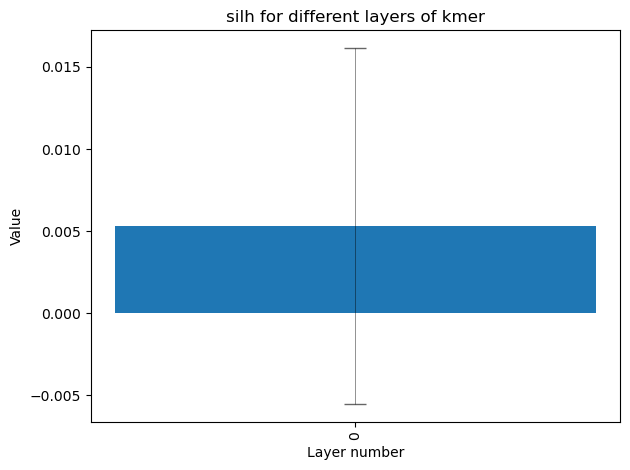

In [4]:
metrics = ['ARI', 'P5', 'silh']
models = ['evo2', 'viralm','dnabert2', 'dnabertS', 'kmer']
models_ = ['Evo2', 'ViraLM', 'DNABERT-2', 'DNABERT-S', 'kmer']
best = {metric: {m: [] for m in models_} for metric in metrics}
for mdl in models:
    for metr in metrics:
        df = pd.read_excel(f'../data/metrics/{mdl}/{metr}.xlsx')
        if mdl == 'evo2':
            mdl_ = 'Evo2'
        elif mdl == 'viralm':
            mdl_ = 'ViraLM'
        elif mdl == 'dnabert2':
            mdl_ = 'DNABERT-2'
        elif mdl == 'dnabertS':
            mdl_ = 'DNABERT-S'
        elif mdl == 'kmer':
            mdl_ = 'kmer'
        if metr == 'P5':
            metr_ = 'Precision@5'
        if metr == 'silh':
            metr_ = 'Silhouette'
        visualize_metrics(df, model_name = mdl_, metric_name = metr, save = True)
        best[metr][mdl_] = (df.mean(axis = 1).argmax(), df.mean(axis = 1).max(), df.iloc[df.mean(axis = 1).argmax(), :].std())

In [5]:
best

{'ARI': {'Evo2': (26, 0.2647423858831617, 0.030689003032618626),
  'ViraLM': (4, 0.20302222100103262, 0.02918951243678916),
  'DNABERT-2': (3, 0.15238883271089224, 0.016751634237532342),
  'DNABERT-S': (4, 0.19474214403717408, 0.027633740429510743),
  'kmer': (0, 0.1467944770623447, 0.022537538050984282)},
 'P5': {'Evo2': (26, 0.6126451934915715, 0.017403519738970554),
  'ViraLM': (2, 0.6373919015233995, 0.017328551326739897),
  'DNABERT-2': (3, 0.5551969580027709, 0.014769499142643186),
  'DNABERT-S': (4, 0.6032615307905397, 0.0159047475400929),
  'kmer': (0, 0.5806840200282636, 0.0159431532558459)},
 'silh': {'Evo2': (29, 0.11000201016664506, 0.018254767561310753),
  'ViraLM': (11, 0.18196040868759156, 0.0096005016444562),
  'DNABERT-2': (6, 0.1252418865263462, 0.00990269032341337),
  'DNABERT-S': (8, 0.13035725936293602, 0.007526986322749725),
  'kmer': (0, 0.005307037980898216, 0.010837921016533409)}}

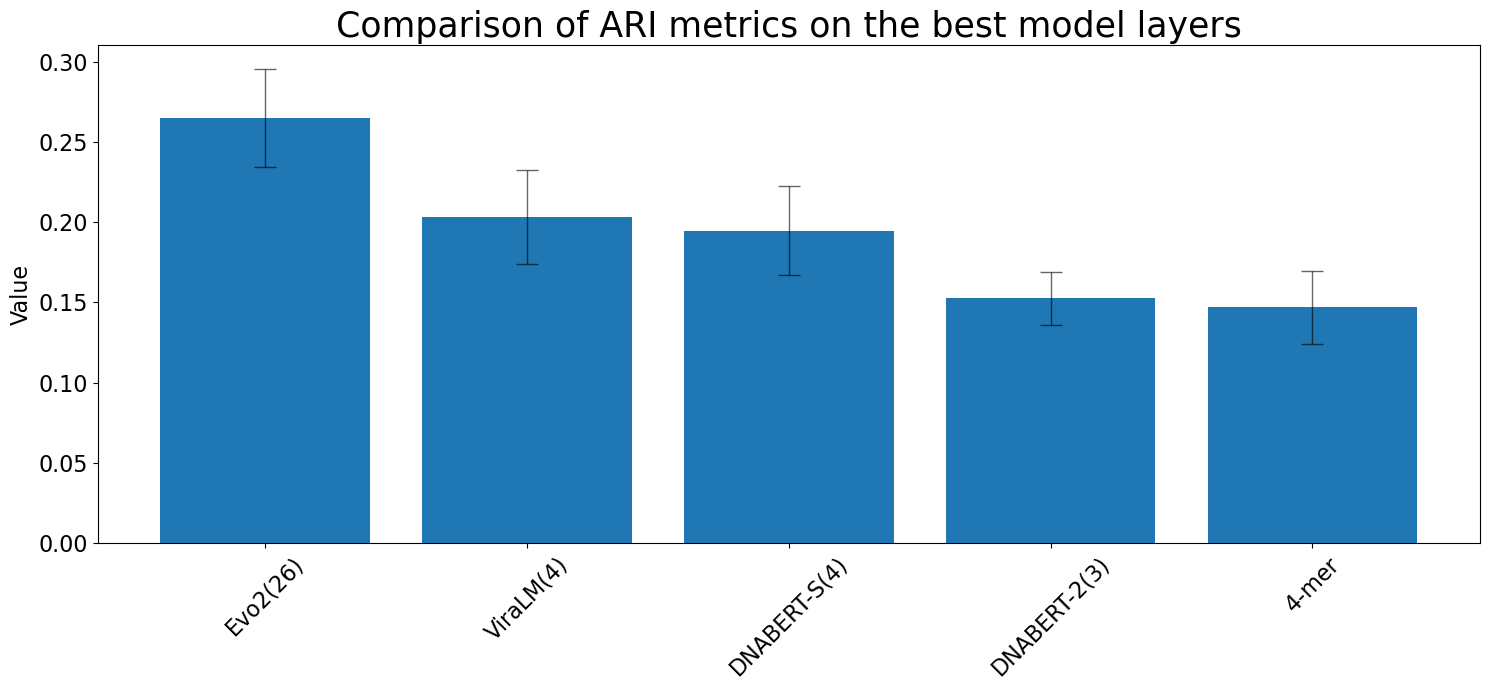

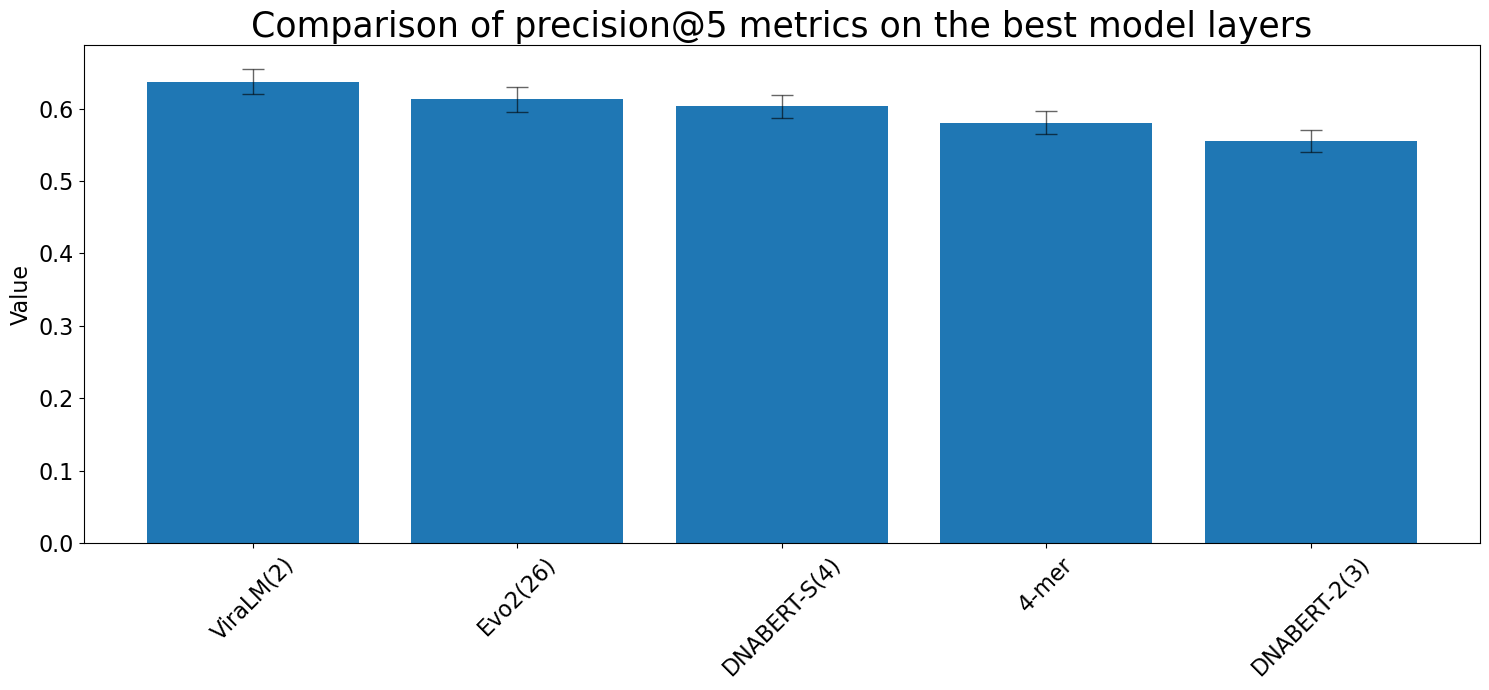

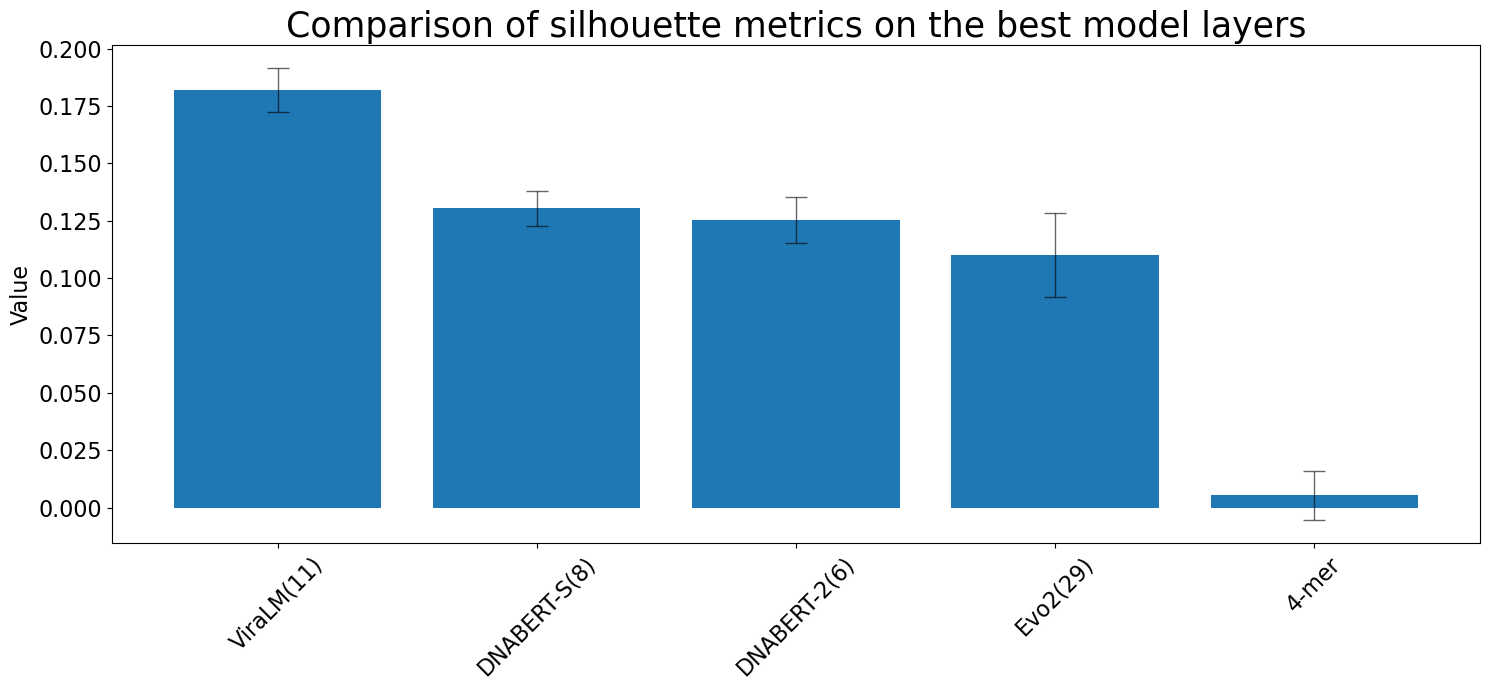

In [7]:
for k in best:    
    
    layers = [(str(x) + '(' + str(best[k][x][0])) + ')' if x != 'kmer' else '4-mer' for x in best[k]]
    means = [best[k][x][1] for x in best[k]]
    stds = [best[k][x][2] for x in best[k]]

    sorted_data = sorted(zip(means, stds, layers), reverse=True)
    means, stds, layers = zip(*sorted_data)

    plt.figure(figsize=(15, 7))
    plt.bar(
        layers,
        means,
        yerr=stds,
        capsize=8,
        error_kw={
            "elinewidth": 1,
            "capthick": 1,
            "alpha": 0.6
        }
    )
    
    if k == 'P5':
        plt.title(f"Comparison of precision@5 metrics on the best model layers", fontsize=25)
    elif k == 'silh':
        plt.title(f"Comparison of silhouette metrics on the best model layers", fontsize=25)
    else:
        plt.title(f"Comparison of {k} metrics on the best model layers", fontsize=25)
    

    plt.ylabel("Value", fontsize=16)
    plt.xticks(rotation=45, fontsize=16)
    plt.yticks(fontsize=16)
    plt.tight_layout()
    plt.savefig(f"../data/metrics/compare_metrics/COMPARE_{k}.png", dpi=300, bbox_inches='tight')
    plt.show()

In [9]:
def visualize_metrics(df, model_name, metric_name, virus, save = False):
    df_sorted = df.sort_index()
    means = df_sorted.mean(axis=1)
    stds = df_sorted.std(axis=1)
    
    layers = df_sorted.index
    
    # Один barplot с "усами"
    plt.figure()
    plt.bar(
        layers,
        means,
        yerr=stds,
        capsize=8,                 
        error_kw={
            "elinewidth": 0.5,     
            "capthick": 1,         
            "alpha": 0.6
        }
    )


    
    plt.title(f"Precision@5 for different layers of {model_name} ({virus})")
    plt.xlabel("Layer number")
    plt.ylabel("Value")

    plt.xticks(layers, rotation=90)
    plt.tight_layout()
    if save:
        plt.savefig(f'../data/metrics/compare_metrics/{model_name}_{metric_name}_{virus}.png')
    plt.show()

../data/metrics/evo2/P@5_matrix_Mriyavirales_preproc.xlsx


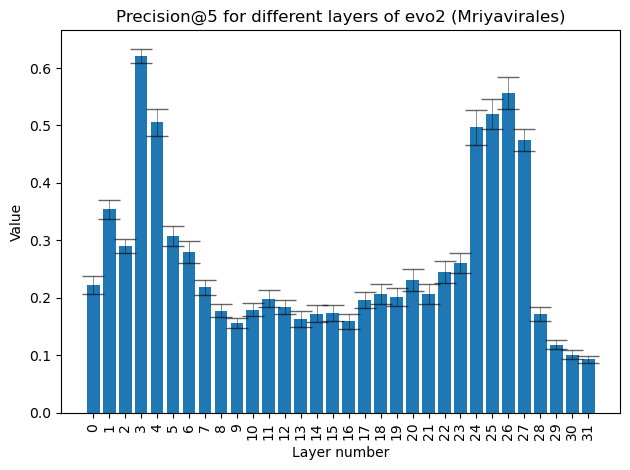

../data/metrics/viralm/P@5_matrix_Mriyavirales_preproc.xlsx


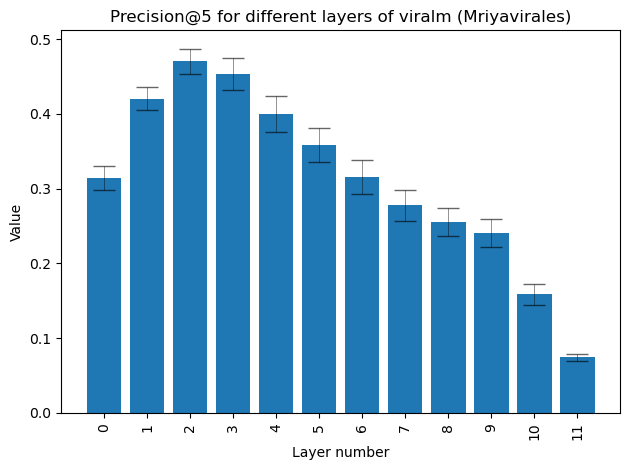

../data/metrics/dnabert2/P@5_matrix_Mriyavirales_preproc.xlsx


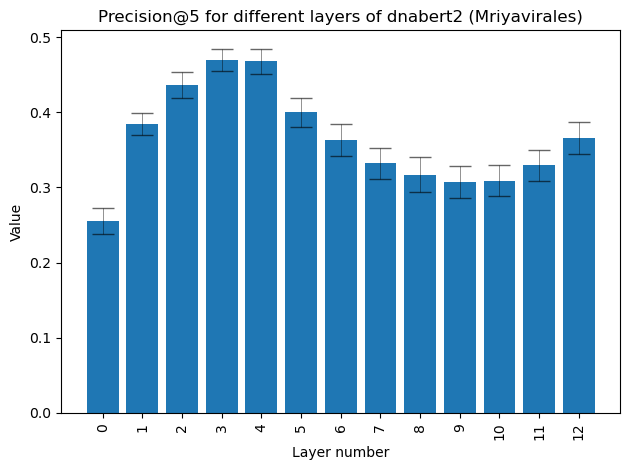

../data/metrics/dnabertS/P@5_matrix_Mriyavirales_preproc.xlsx


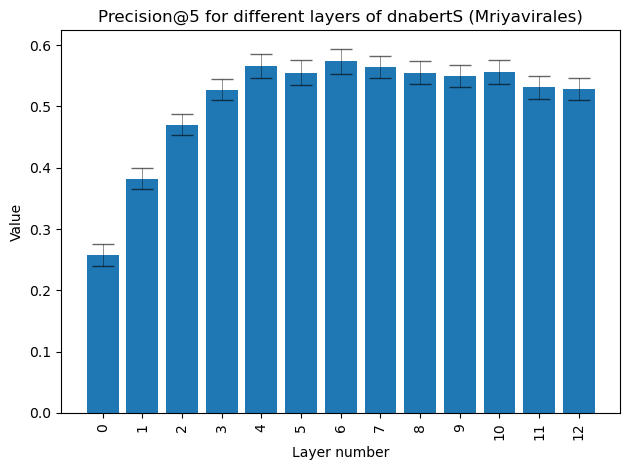

../data/metrics/kmer/P@5_matrix_Mriyavirales_preproc.xlsx


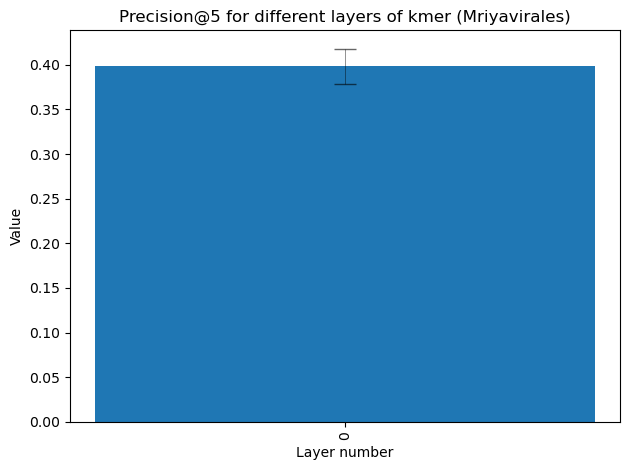

../data/metrics/evo2/P@5_matrix_Egovirales_preproc.xlsx


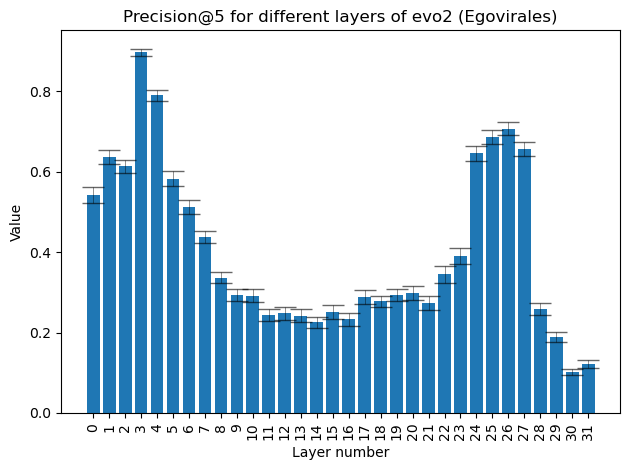

../data/metrics/viralm/P@5_matrix_Egovirales_preproc.xlsx


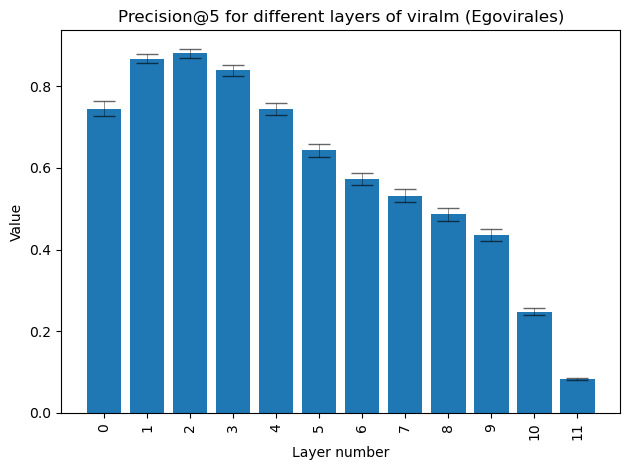

../data/metrics/dnabert2/P@5_matrix_Egovirales_preproc.xlsx


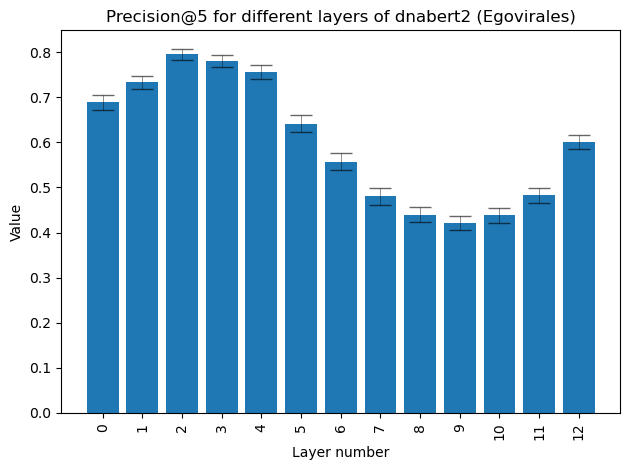

../data/metrics/dnabertS/P@5_matrix_Egovirales_preproc.xlsx


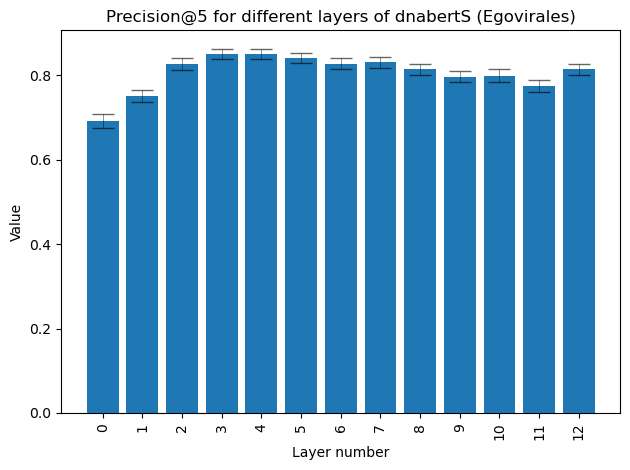

../data/metrics/kmer/P@5_matrix_Egovirales_preproc.xlsx


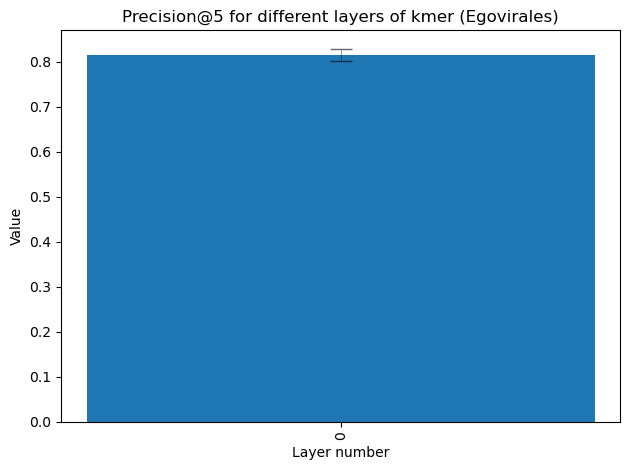

../data/metrics/evo2/P@5_matrix_REVERSECOMPLEMENTMriyavirales_preproc.xlsx


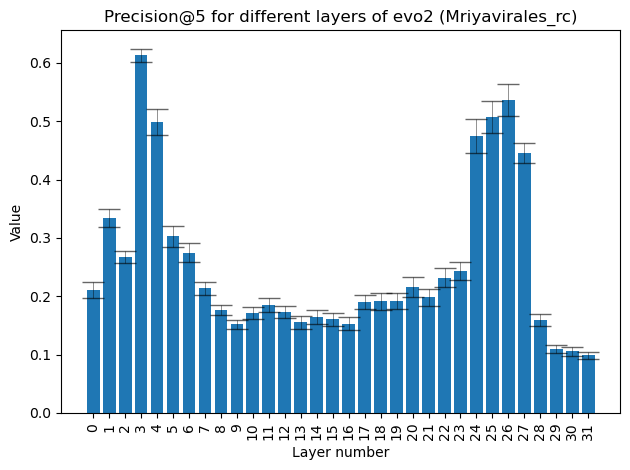

../data/metrics/viralm/P@5_matrix_REVERSECOMPLEMENTMriyavirales_preproc.xlsx


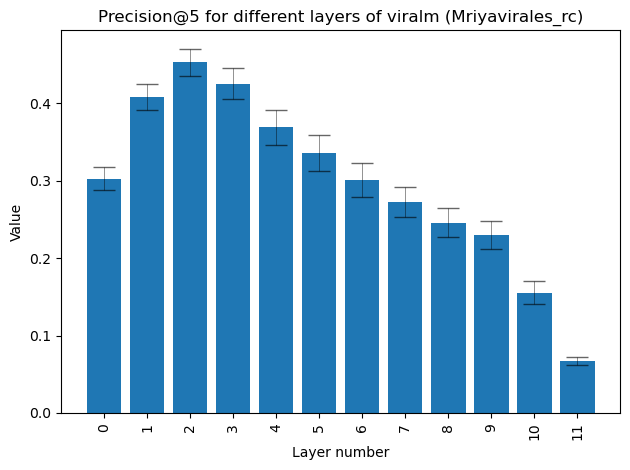

../data/metrics/dnabert2/P@5_matrix_REVERSECOMPLEMENTMriyavirales_preproc.xlsx


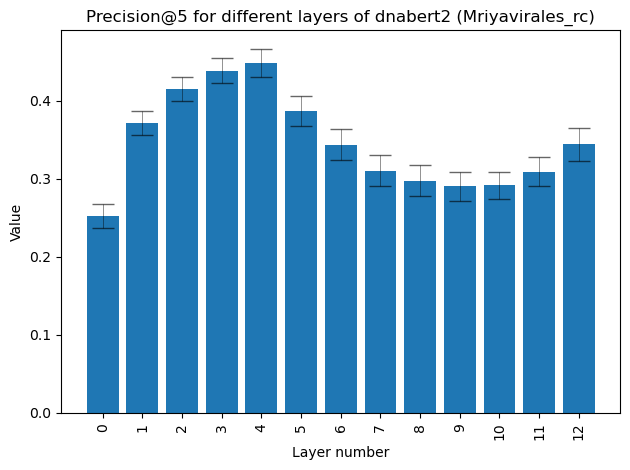

../data/metrics/dnabertS/P@5_matrix_REVERSECOMPLEMENTMriyavirales_preproc.xlsx


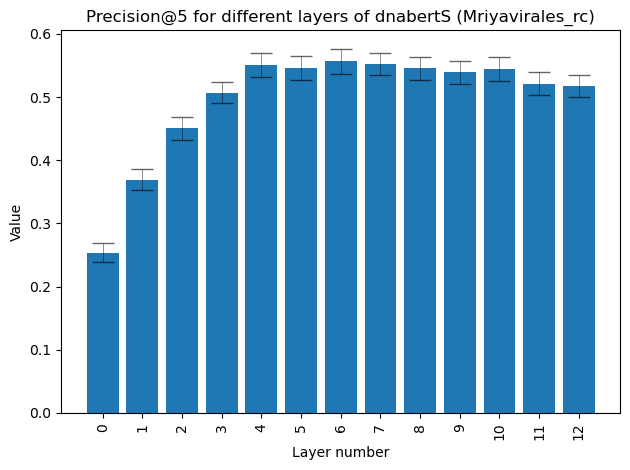

../data/metrics/kmer/P@5_matrix_REVERSECOMPLEMENTMriyavirales_preproc.xlsx


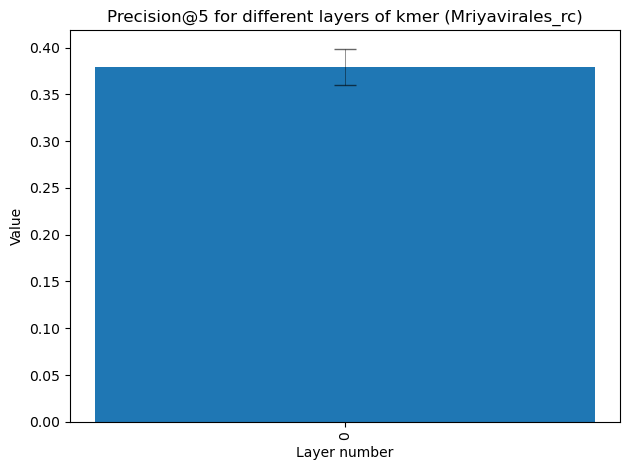

../data/metrics/evo2/P@5_matrix_REVERSECOMPLEMENTEgovirales_preproc.xlsx


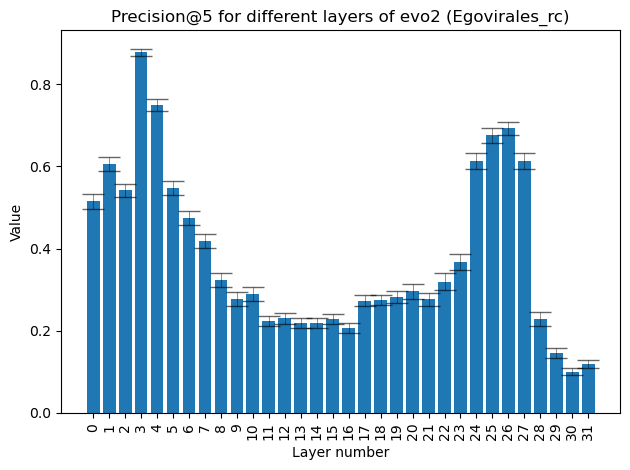

../data/metrics/viralm/P@5_matrix_REVERSECOMPLEMENTEgovirales_preproc.xlsx


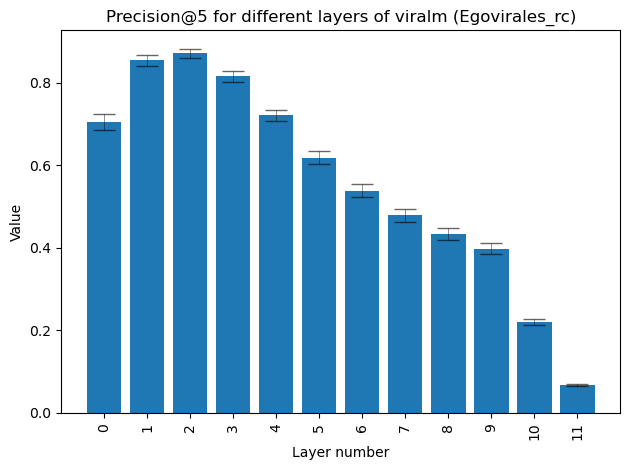

../data/metrics/dnabert2/P@5_matrix_REVERSECOMPLEMENTEgovirales_preproc.xlsx


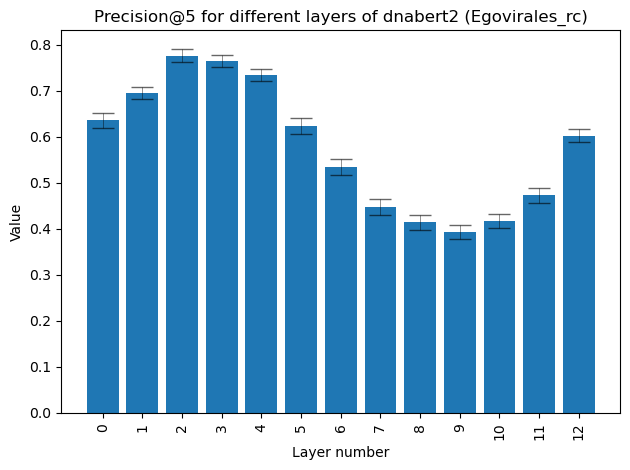

../data/metrics/dnabertS/P@5_matrix_REVERSECOMPLEMENTEgovirales_preproc.xlsx


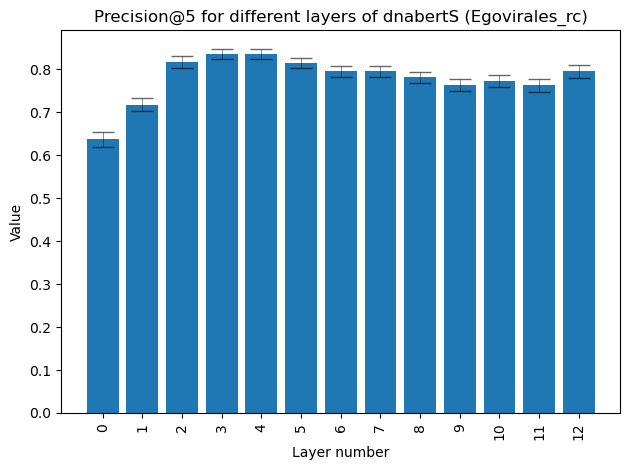

../data/metrics/kmer/P@5_matrix_REVERSECOMPLEMENTEgovirales_preproc.xlsx


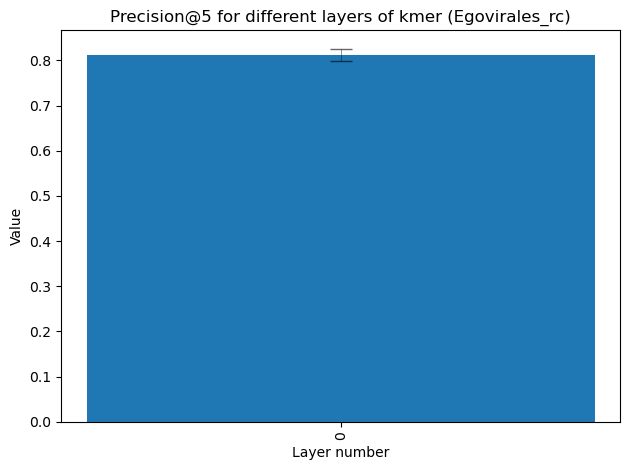

In [11]:
metrics = ['P@5']
UNK_viruses = ['Mriyavirales_preproc', 'Egovirales_preproc', 'REVERSECOMPLEMENTMriyavirales_preproc', 'REVERSECOMPLEMENTEgovirales_preproc']
models = ['evo2', 'viralm','dnabert2', 'dnabertS', 'kmer']

best = {vir: {metric: {m: [] for m in models} for metric in metrics} for vir in UNK_viruses}

for vir in UNK_viruses:
    for mdl in models:
        for metr in metrics:
            path = f'../data/metrics/{mdl}/{metr}_matrix_{vir}.xlsx'
            df = pd.read_excel(path)
            print(path)
            df = df.iloc[:, 1:]
            if vir.startswith('REVERSECOMPLEMENT'):
                name = f'{vir.split('REVERSECOMPLEMENT')[-1].split('_')[0]}' + '_rc'
            else:
                name = f'{vir.split('_')[0]}'
                
            visualize_metrics(df.iloc[:, 1:], model_name = mdl, virus = name, metric_name = metr, save = True)
            if metr == 'P@K' or metr == 'P@1' or metr == 'P@5':
                best[vir][metr][mdl] = (df.mean(axis = 1).argmax(), df.mean(axis = 1).max(), df.iloc[df.mean(axis = 1).argmax(), :].std())
            else:
                best[vir][metr][mdl] = (df.mean(axis = 1).argmin(), df.mean(axis = 1).min(), df.iloc[df.mean(axis = 1).argmin(), :].std())

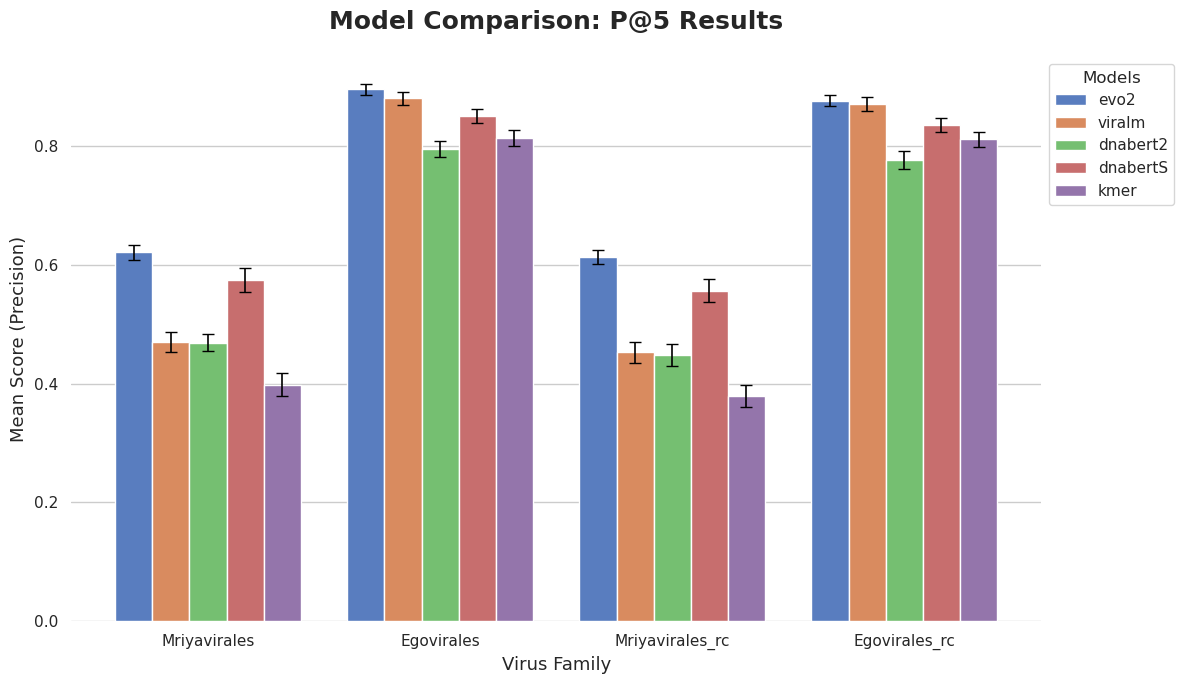

In [14]:
data_list = []
for vir, metrics_dict in best.items():
    clean_name = f"{vir.split('REVERSECOMPLEMENT')[-1].split('_')[0]}_rc" if "REVERSECOMPLEMENT" in vir else vir.split('_')[0]
    for metr, models_dict in metrics_dict.items():
        for mdl, results in models_dict.items():
            data_list.append({
                'Virus': clean_name,
                'Model': mdl,
                'Metric': metr,
                'Score': results[1],
                'Std': results[2]
            })

df_plot = pd.DataFrame(data_list)

sns.set_theme(style="whitegrid", palette="muted")
fig, ax = plt.subplots(figsize=(12, 7))

model_order = models
sns.barplot(
    data=df_plot, 
    x='Virus', 
    y='Score', 
    hue='Model', 
    hue_order=model_order,
    ax=ax
)


for i, model_name in enumerate(model_order):
    model_data = df_plot[df_plot['Model'] == model_name].set_index('Virus').reindex(df_plot['Virus'].unique())
    
    x_coords = [patch.get_x() + patch.get_width() / 2 for patch in ax.containers[i]]
    y_coords = model_data['Score'].values
    y_err = model_data['Std'].values
    
    ax.errorbar(
        x_coords, y_coords, yerr=y_err, 
        fmt='none', c='black', capsize=4, elinewidth=1.2, zorder=3
    )

ax.set_title(f'Model Comparison: {metrics[0]} Results', fontsize=18, fontweight='bold', pad=20)
ax.set_ylabel('Mean Score (Precision)', fontsize=13)
ax.set_xlabel('Virus Family', fontsize=13)

ax.legend(title='Models', bbox_to_anchor=(1, 1), loc='upper left', frameon=True)
sns.despine(left=True, bottom=True)

plt.tight_layout()
plt.savefig(f'../data/metrics/compare_metrics/Model_comparison_new_vir.png')
plt.show()

In [15]:
best

{'Mriyavirales_preproc': {'P@5': {'evo2': (3,
    0.6212666666666666,
    0.01237087501969182),
   'viralm': (2, 0.4700917056530215, 0.016993601985864106),
   'dnabert2': (3, 0.46930666666666654, 0.014492759940844514),
   'dnabertS': (6, 0.5741866666666668, 0.020375962896157274),
   'kmer': (0, 0.39812000000000003, 0.01943822822567138)}},
 'Egovirales_preproc': {'P@5': {'evo2': (3,
    0.8964065573770492,
    0.009437668303481713),
   'viralm': (2, 0.8808263851528534, 0.01140199136411031),
   'dnabert2': (2, 0.7958098360655739, 0.013355648097797147),
   'dnabertS': (4, 0.8510229508196722, 0.0122265093457727),
   'kmer': (0, 0.8145311475409837, 0.013870091778593732)}},
 'REVERSECOMPLEMENTMriyavirales_preproc': {'P@5': {'evo2': (3,
    0.61328,
    0.012048910151032923),
   'viralm': (2, 0.453161544834308, 0.017447581708671722),
   'dnabert2': (4, 0.4480133333333333, 0.018380207238782427),
   'dnabertS': (6, 0.5569400000000001, 0.01998601438444034),
   'kmer': (0, 0.37903333333333333, 0.

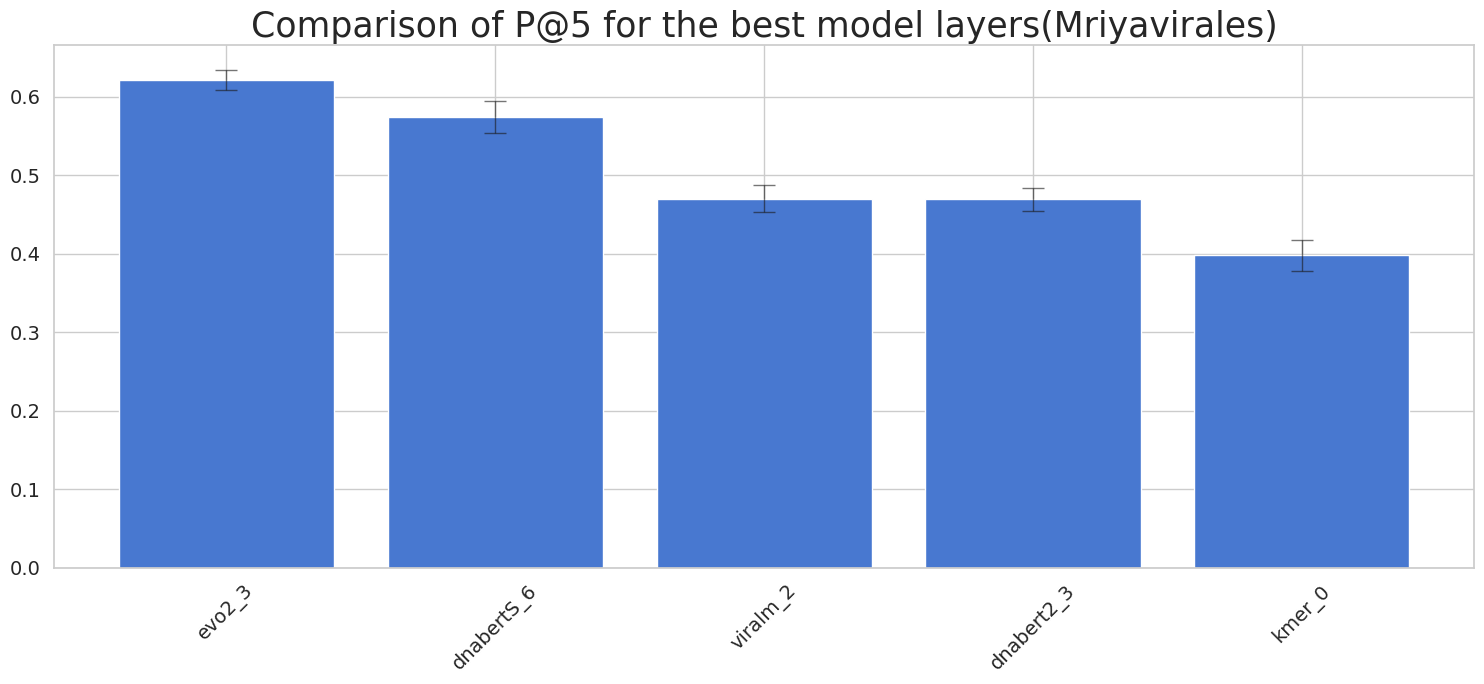

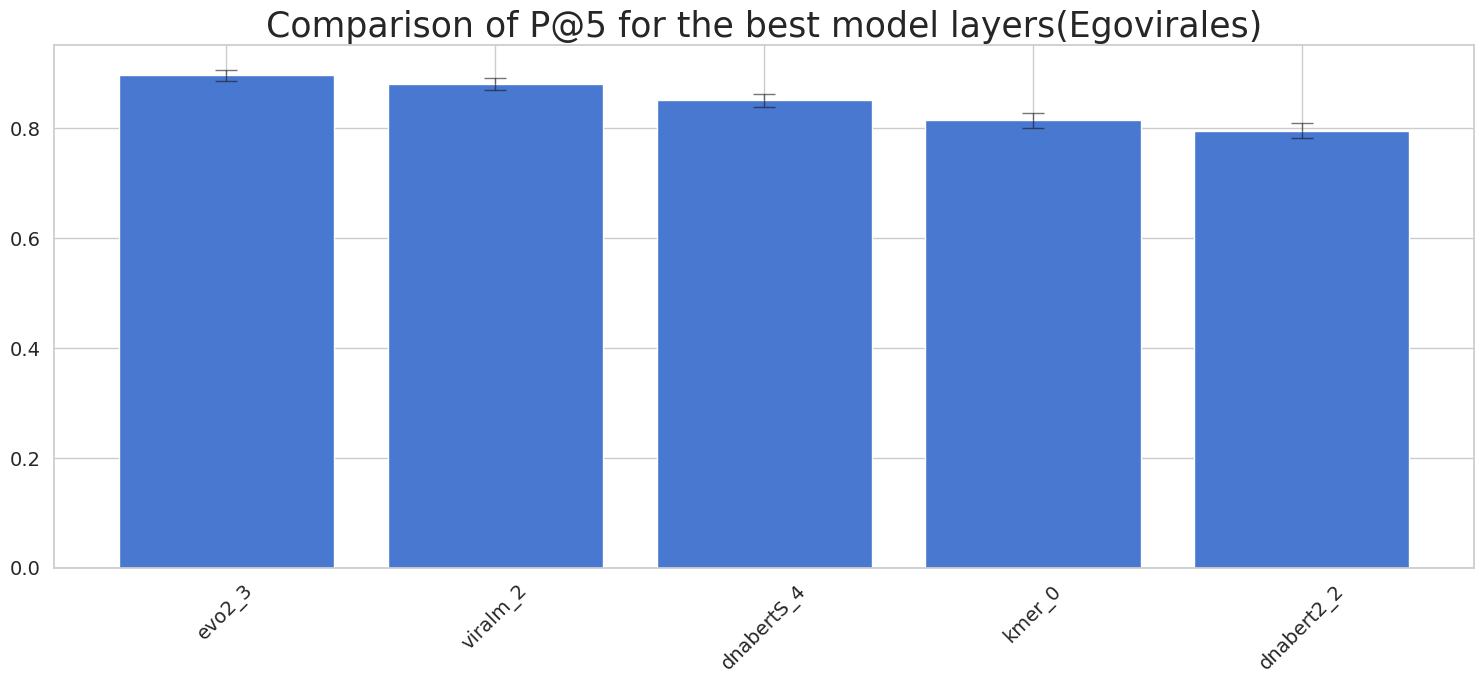

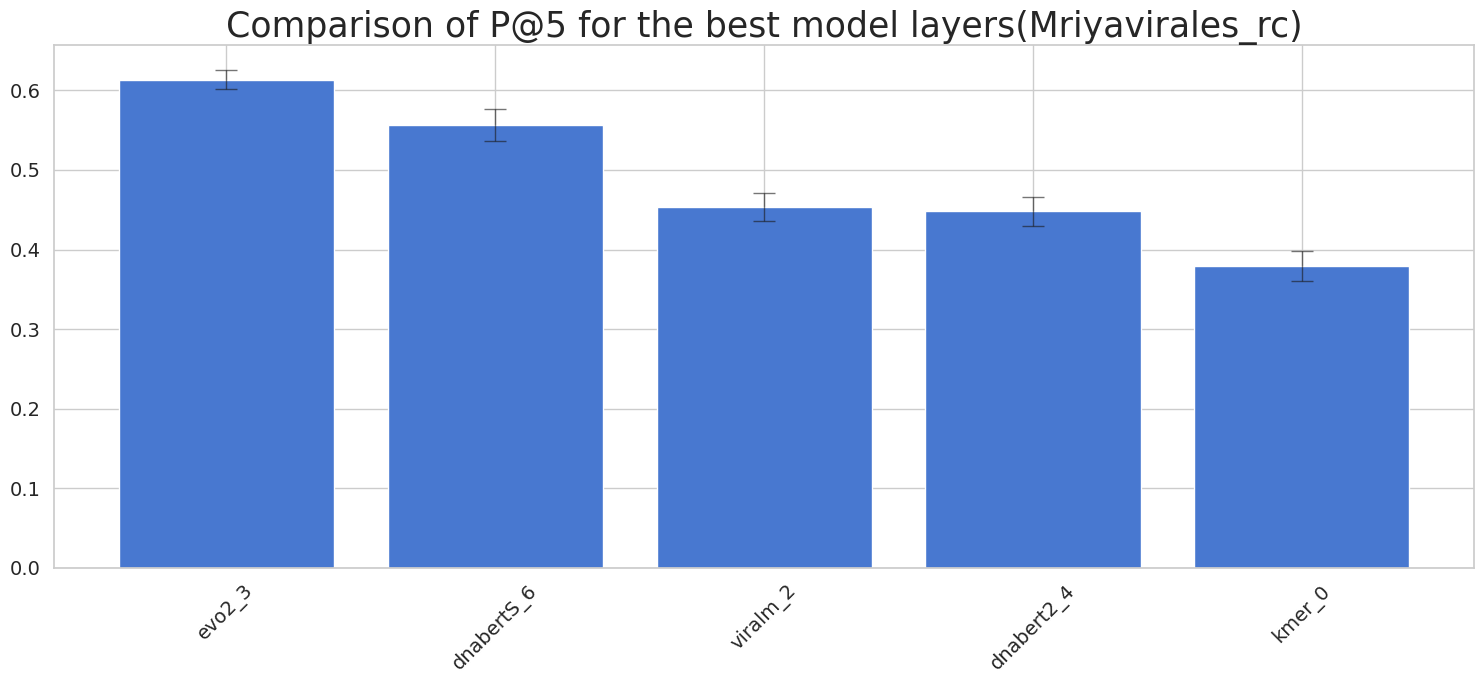

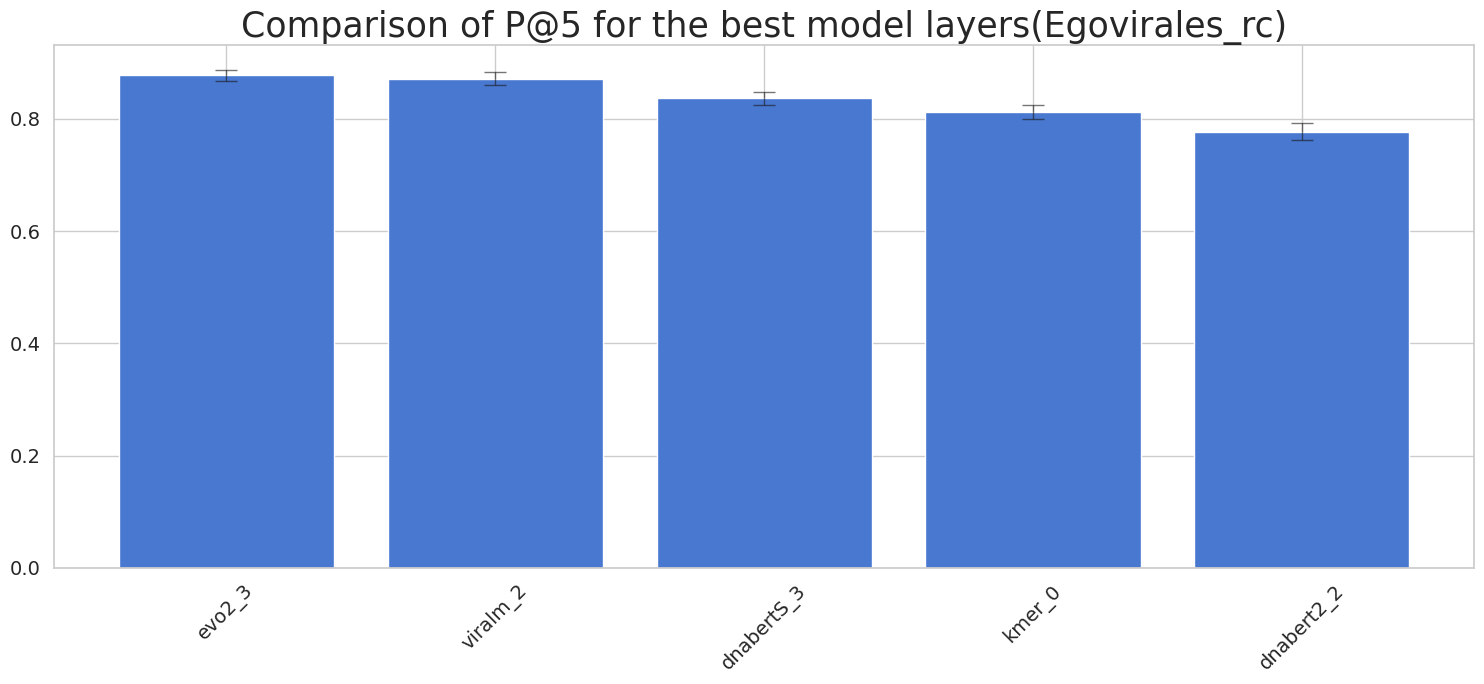

In [22]:
for vir in UNK_viruses:
    for k in best[vir]:
        
        layers = [(str(x) + '_' + str(best[vir][k][x][0])) for x in best[vir][k]]
        means = [best[vir][k][x][1] for x in best[vir][k]]
        stds = [best[vir][k][x][2] for x in best[vir][k]]

        sorted_data = sorted(zip(means, stds, layers), reverse=True)
        means, stds, layers = zip(*sorted_data)

        plt.figure(figsize=(15, 7))
        plt.bar(
            layers,
            means,
            yerr=stds,
            capsize=8,
            error_kw={
                "elinewidth": 1,
                "capthick": 1,
                "alpha": 0.6
            }
        )

        if vir.startswith('REVERSECOMPLEMENT'):
            name = f'{vir.split('REVERSECOMPLEMENT')[-1].split('_')[0]}' + '_rc'
        else:
            name = f'{vir.split('_')[0]}'
        plt.title(f"Comparison of {k} for the best model layers({name})", fontsize = 25)
        plt.xticks(rotation=45, fontsize=14)
        plt.yticks(fontsize=14)
        plt.tight_layout()
        plt.savefig(f"../data/metrics/compare_metrics/COMPARE_{k}_{name}.png")
        plt.show()

In [26]:
df = pd.read_excel('../data/metrics/P@K_new_virus/P@5.xlsx')
best = {}

for _, row in df[df['type'] == 'cross'].iterrows():
    vir = row['virus']
    metr = row['type']
    mdl = row['model']
    
    if vir not in best:
        best[vir] = {}
    if metr not in best[vir]:
        best[vir][metr] = {}
    
    
    best[vir][metr][mdl] = (
        row['best_layer'], 
        row['mean_P@K'], 
        row['std_P@K']
    )

In [27]:
best

{'Mriyavirales_preproc': {'cross': {'kmer': ('-', 0.3405, 0.0193),
   'dnabert2': (4, 0.4831, 0.0177),
   'viralm': (3, 0.4627, 0.0156),
   'dnabertS': (7, 0.6522, 0.0155),
   'evo2': (3, 0.698, 0.011)}},
 'Egovirales_preproc': {'cross': {'kmer': ('-', 0.6107, 0.0224),
   'dnabertS': (12, 0.8487, 0.0121),
   'dnabert2': (2, 0.6547, 0.021),
   'viralm': (3, 0.7814, 0.0156),
   'evo2': (3, 0.8814, 0.0095)}}}

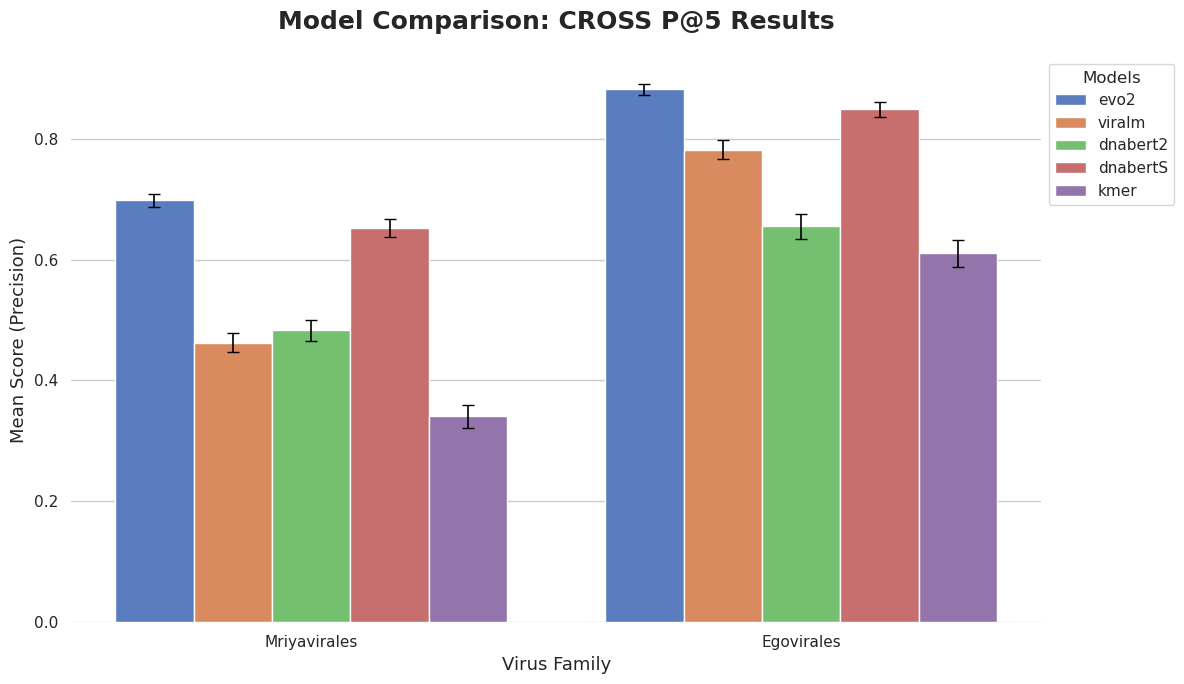

In [28]:
data_list = []
for vir, metrics_dict in best.items():
    clean_name = f"{vir.split('REVERSECOMPLEMENT')[-1].split('_')[0]}_rc" if "REVERSECOMPLEMENT" in vir else vir.split('_')[0]
    for metr, models_dict in metrics_dict.items():
        for mdl, results in models_dict.items():
            data_list.append({
                'Virus': clean_name,
                'Model': mdl,
                'Metric': metr,
                'Score': results[1],
                'Std': results[2]
            })

df_plot = pd.DataFrame(data_list)

sns.set_theme(style="whitegrid", palette="muted")
fig, ax = plt.subplots(figsize=(12, 7))

model_order = models
sns.barplot(
    data=df_plot, 
    x='Virus', 
    y='Score', 
    hue='Model', 
    hue_order=model_order,
    ax=ax
)
for i, model_name in enumerate(model_order):
    model_data = df_plot[df_plot['Model'] == model_name].set_index('Virus').reindex(df_plot['Virus'].unique())
    
    x_coords = [patch.get_x() + patch.get_width() / 2 for patch in ax.containers[i]]
    y_coords = model_data['Score'].values
    y_err = model_data['Std'].values
    
    ax.errorbar(
        x_coords, y_coords, yerr=y_err, 
        fmt='none', c='black', capsize=4, elinewidth=1.2, zorder=3
    )

ax.set_title(f'Model Comparison: CROSS {metrics[0]} Results', fontsize=18, fontweight='bold', pad=20)
ax.set_ylabel('Mean Score (Precision)', fontsize=13)
ax.set_xlabel('Virus Family', fontsize=13)

ax.legend(title='Models', bbox_to_anchor=(1, 1), loc='upper left', frameon=True)
sns.despine(left=True, bottom=True)

plt.tight_layout()
plt.savefig(f'../data/metrics/compare_metrics/Model_comparison_CROSS_new_vir.png')
plt.show()